# Employee Turnover Prediction
**Machine Learning Unit End Project 1 · Portobello Tech**

This project examines which work patterns are associated with turnover, groups employees who left, and compares three classifiers for flagging employees who may benefit from retention support. The positive class is `left = 1`.

**Run this notebook:** Keep `HR_comma_sep.csv` beside the notebook. Install the packages in `requirements.txt` in your Python environment, open the notebook in Jupyter, and select **Restart Kernel and Run All Cells**. The saved notebook includes the results and figures.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
    confusion_matrix, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 123
sns.set_theme(style="whitegrid", palette="colorblind")

## 1. Data quality

The supplied CSV names the department field `sales`. It is renamed to `Department` to match the assignment. The CSV has no employee identifier, so exact duplicate rows could represent repeated records or different employees with identical recorded attributes. This analysis keeps one copy of each exact row so identical labeled records cannot inflate held-out performance. This choice changes the observed turnover rate and may remove genuine employees with identical records.

In [2]:
raw = pd.read_csv(Path("HR_comma_sep.csv")).rename(columns={"sales": "Department"})
print(f"Source shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.isna().sum().rename("Missing values").to_frame())
assert raw.isna().sum().sum() == 0, "Resolve missing values before modeling."
assert set(raw["left"].unique()) == {0, 1}, "Expected binary turnover labels."
assert raw[["satisfaction_level", "last_evaluation"]].apply(
    lambda col: col.between(0, 1).all()
).all(), "Expected satisfaction and evaluation scores in [0, 1]."
print(f"Exact duplicates beyond first occurrence: {raw.duplicated().sum():,}")

df = raw.drop_duplicates().copy()
print(f"Rows retained: {len(df):,}")
print(f"Turnover rate before cleaning: {raw['left'].mean():.1%}")
print(f"Turnover rate after cleaning: {df['left'].mean():.1%}")
display(df["left"].value_counts().rename("Cleaned count").to_frame())

Source shape: 14,999 rows × 10 columns


,Missing values
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
Department,0
salary,0


Exact duplicates beyond first occurrence: 3,008
Rows retained: 11,991
Turnover rate before cleaning: 23.8%
Turnover rate after cleaning: 16.6%


,Cleaned count
left,
0,10000
1,1991


## 2. Exploratory data analysis

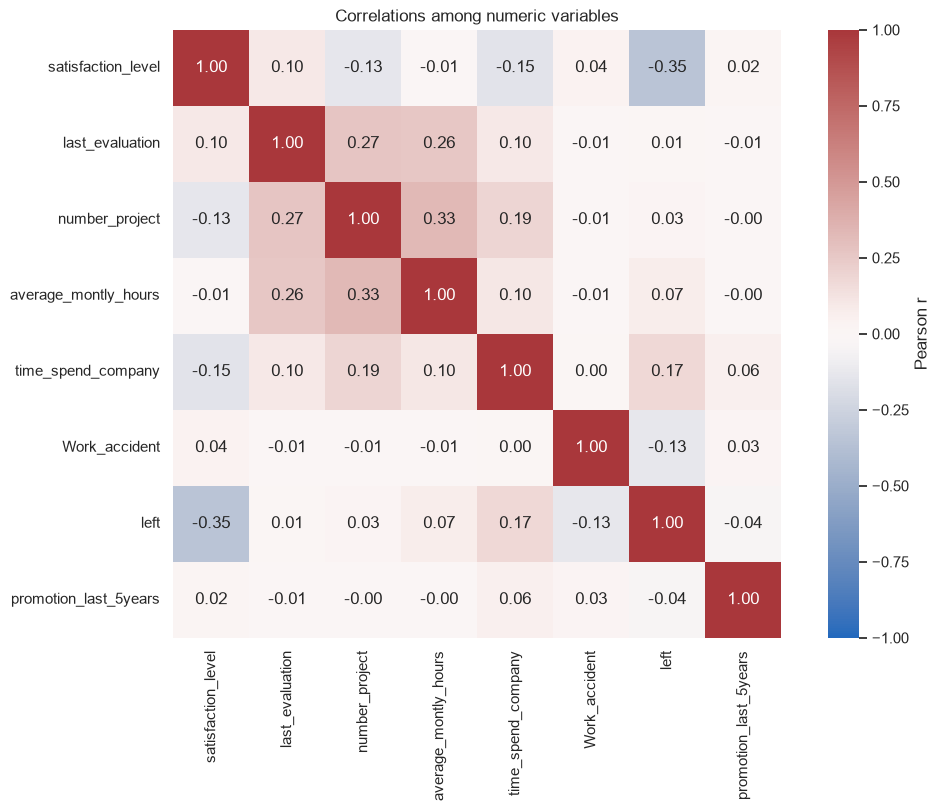

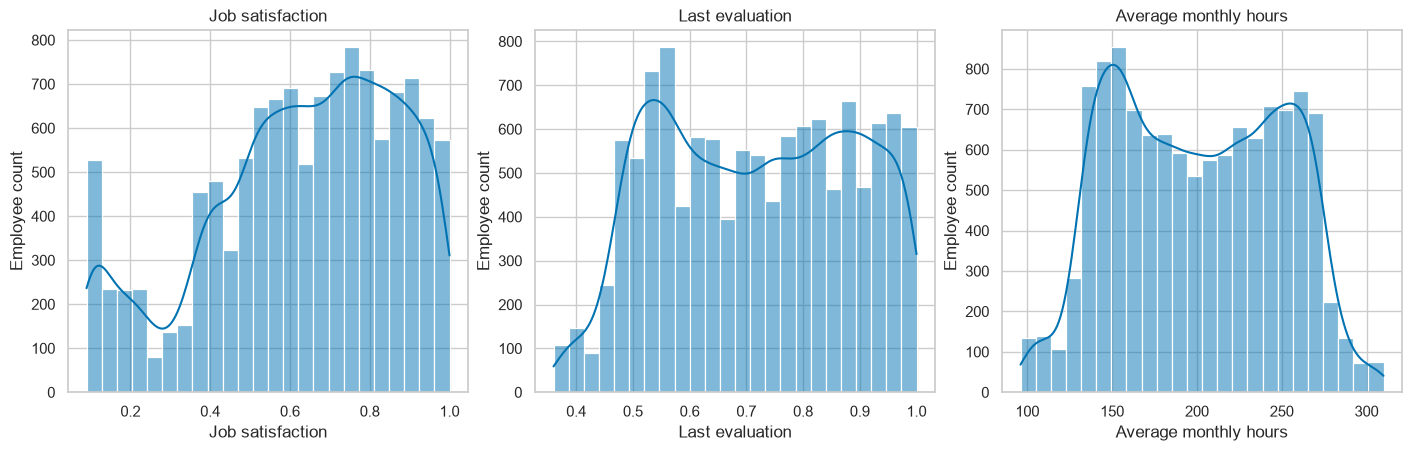

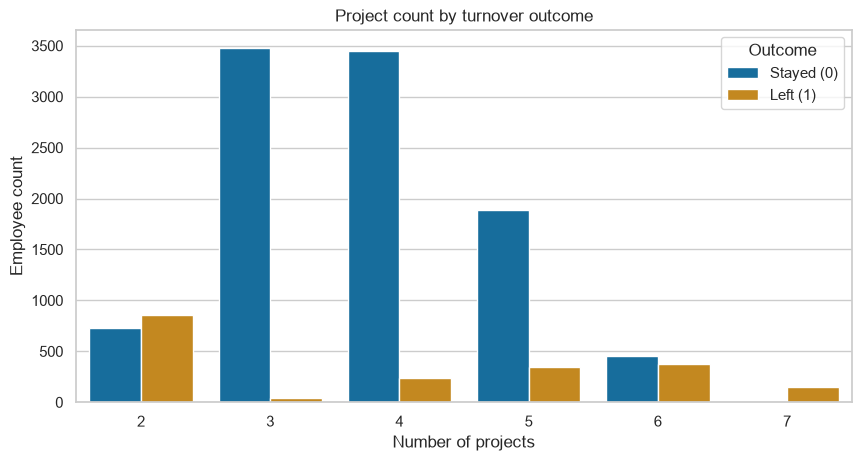

,employees,left,turnover_rate
number_project,,,
2,1582,857,54.2%
3,3520,38,1.1%
4,3685,237,6.4%
5,2233,343,15.4%
6,826,371,44.9%
7,145,145,100.0%


,employees,turnover_rate
salary,,
high,990,4.8%
low,5740,20.5%
medium,5261,14.6%


In [3]:
correlation = df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
sns.heatmap(
    correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
    cmap="vlag", square=True, ax=ax, cbar_kws={"label": "Pearson r"},
)
ax.set_title("Correlations among numeric variables")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
distributions = {
    "satisfaction_level": "Job satisfaction",
    "last_evaluation": "Last evaluation",
    "average_montly_hours": "Average monthly hours",
}
for ax, (column, label) in zip(axes, distributions.items()):
    sns.histplot(df[column], bins=24, kde=True, ax=ax)
    ax.set(xlabel=label, title=label, ylabel="Employee count")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
sns.countplot(data=df, x="number_project", hue="left", ax=ax)
ax.set(title="Project count by turnover outcome", xlabel="Number of projects",
       ylabel="Employee count")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Stayed (0)", "Left (1)"], title="Outcome")
plt.show()

project_stats = df.groupby("number_project")["left"].agg(
    employees="size", left="sum", turnover_rate="mean"
)
display(project_stats.style.format({"turnover_rate": "{:.1%}"}))
salary_stats = df.groupby("salary")["left"].agg(employees="size", turnover_rate="mean")
display(salary_stats.style.format({"turnover_rate": "{:.1%}"}))

Satisfaction has the largest absolute Pearson correlation with turnover among numeric predictors (−0.35). Tenure has a smaller positive association (+0.17), and the work accident flag has a negative association (−0.13). Low-salary employees left at 20.5%, versus 4.8% for high-salary employees. These are descriptive associations that can reflect differences in job roles and other unmeasured factors.

The project-count plot shows a nonlinear relationship. Turnover was 54.2% at two projects, dropped to 1.1% at three, and rose to 44.9% at six. All 145 retained rows with seven projects show turnover. The two-project group contributed the largest number of departures (857). That pattern makes low and high project counts worth examining separately, even though project count has a near-zero linear correlation with turnover. Project counts alone cannot distinguish underassignment from employees winding down work before departure.

## 3. Cluster employees who left

Use `left` to filter employees and fit K-means to satisfaction and last evaluation. Both scores are on a 0–1 scale, so the cluster centers are reported in the original units. Cluster IDs are ordered by satisfaction for readability. Clustering is descriptive and its outputs are kept separate from the prediction models.

,satisfaction_level,last_evaluation,employees
cluster,,,
1,0.111,0.869,534
2,0.410,0.517,902
3,0.806,0.913,555


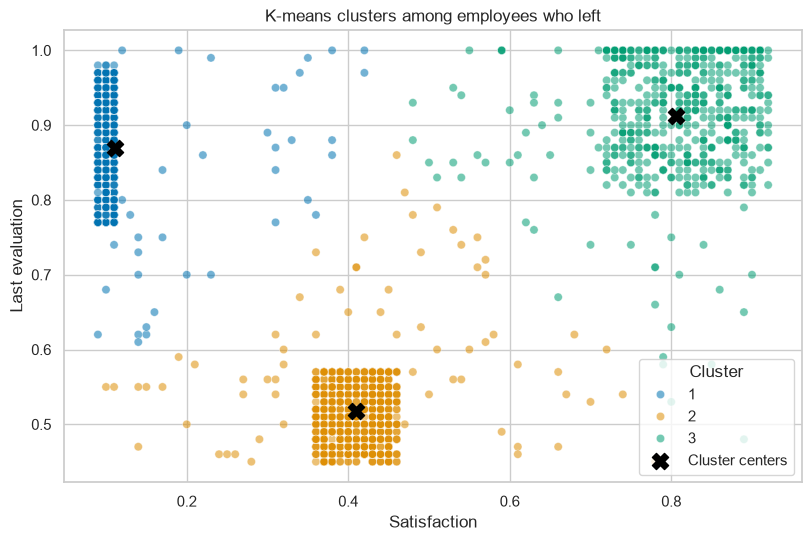

In [4]:
leavers = df[["satisfaction_level", "last_evaluation", "left"]].query("left == 1").copy()
cluster_features = ["satisfaction_level", "last_evaluation"]
kmeans = KMeans(n_clusters=3, n_init=20, random_state=SEED)
labels = kmeans.fit_predict(leavers[cluster_features])
centers = pd.DataFrame(kmeans.cluster_centers_, columns=cluster_features)
centers = centers.sort_values("satisfaction_level")
ordered_ids = {original: ordered for ordered, original in enumerate(centers.index, 1)}
leavers["cluster"] = pd.Series(labels, index=leavers.index).map(ordered_ids)
centers.index = pd.Index(range(1, 4), name="cluster")
centers["employees"] = leavers["cluster"].value_counts().sort_index()
display(centers.round(3))

fig, ax = plt.subplots(figsize=(8, 5.3), layout="constrained")
sns.scatterplot(data=leavers, x=cluster_features[0], y=cluster_features[1],
                hue="cluster", palette="colorblind", alpha=.55, ax=ax)
ax.scatter(centers[cluster_features[0]], centers[cluster_features[1]],
           marker="X", s=135, c="black", label="Cluster centers")
ax.legend(title="Cluster")
ax.set(xlabel="Satisfaction", ylabel="Last evaluation",
       title="K-means clusters among employees who left")
plt.show()

- **Cluster 1** has the lowest satisfaction and high evaluations. Explore whether workload, recognition, or manager support contributed to dissatisfaction.
- **Cluster 2** has lower satisfaction and lower evaluations. Ask about role fit, training needs, and whether performance expectations were clear.
- **Cluster 3** has high satisfaction and high evaluations. Ask about advancement, compensation, and career options.

These are hypotheses for follow-up conversations. The two cluster inputs cannot establish why an individual left.

## 4. Stratified split, one-hot encoding, and SMOTE

Split the cleaned records 80:20 with `random_state=123`, preserving class proportions. Convert categorical columns with `get_dummies()` and combine them with the numeric columns. Align the test columns to the training schema. During cross-validation, standardization and SMOTE are fitted inside each fold using its training portion. Validation folds and the held-out test set keep their natural class distribution.

The required vanilla SMOTE method interpolates numeric features, so some synthetic rows have fractional dummy or binary values. These are training points and should not be interpreted as actual employee profiles.

In [5]:
X = df.drop(columns="left")
y = df["left"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=SEED
)

categorical = X_train_raw.select_dtypes(exclude="number").columns
numeric = X_train_raw.select_dtypes(include="number").columns

def encode(frame):
    # Combine numeric features with one-hot encoded categorical features.
    dummies = pd.get_dummies(frame[categorical], dtype=float)
    return pd.concat([frame[numeric], dummies], axis=1)

X_train = encode(X_train_raw)
X_test = encode(X_test_raw).reindex(columns=X_train.columns, fill_value=0)
assert X_train.index.intersection(X_test.index).empty
assert X_train.columns.equals(X_test.columns)
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Numeric features: {len(numeric)} | Categorical fields: {list(categorical)}")
print(f"Total encoded features: {X_train.shape[1]}")

# Show what SMOTE produces on the full training set. Cross-validation
# will independently resample the training portion of each fold.
scaled_train = StandardScaler().fit_transform(X_train)
_, y_resampled = SMOTE(random_state=SEED).fit_resample(scaled_train, y_train)
display(pd.DataFrame({
    "Training before SMOTE": y_train.value_counts(),
    "Training after SMOTE": y_resampled.value_counts(),
    "Held-out test": y_test.value_counts(),
}).sort_index().rename_axis("left"))

Training rows: 9,592 | Test rows: 2,399
Numeric features: 7 | Categorical fields: ['Department', 'salary']
Total encoded features: 20


,Training before SMOTE,Training after SMOTE,Held-out test
left,,,
0,7999,7999,2001
1,1593,7999,398


## 5. Five-fold cross-validation and model selection

Use the same five shuffled, stratified folds for logistic regression, random forest, and gradient boosting. Select the model by highest mean validation average precision (AP), a summary of the precision–recall curve that emphasizes how well the model ranks the minority class. Compare ROC AUC, precision, recall, and F1 alongside AP. The cross-validation table uses the default 0.50 cutoff for precision, recall, and F1.

In [6]:
estimators = {
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
}
models = {
    name: Pipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=SEED)),
        ("classifier", estimator),
    ])
    for name, estimator in estimators.items()
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["average_precision", "roc_auc", "precision", "recall", "f1"]
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring=scoring,
                            error_score="raise")
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["AP fold SD"] = scores["test_average_precision"].std(ddof=1)
    cv_rows.append(row)

cv_summary = pd.DataFrame(cv_rows).set_index("Model").sort_values(
    "average_precision", ascending=False
)
display(cv_summary.round(3))
best_name = cv_summary.index[0]
print(f"Selected by mean validation AP: {best_name}")

,average_precision,roc_auc,precision,recall,f1,AP fold SD
Model,,,,,,
Gradient boosting,0.967,0.986,0.907,0.930,0.919,0.006
Random forest,0.963,0.981,0.974,0.909,0.940,0.008
Logistic regression,0.386,0.841,0.415,0.829,0.553,0.007


Selected by mean validation AP: Gradient boosting


## 6. Held-out test performance

Refit each pipeline on the full training set. The test set provides the final ROC curves, confusion matrices, and classification reports. Classification heatmaps include class-level and aggregate scores. Their support values are printed in the accompanying table.

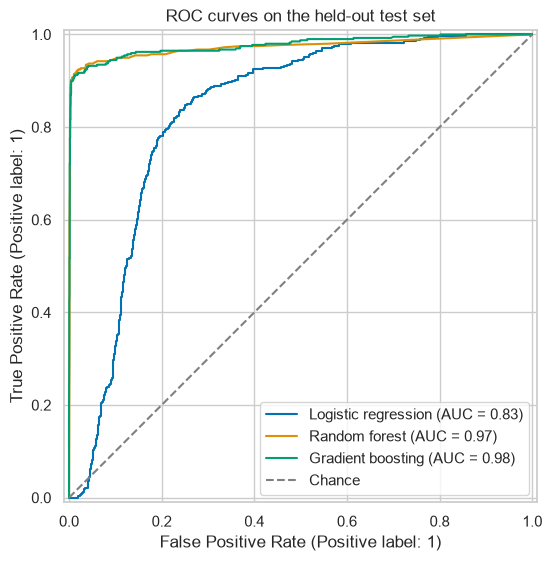

,ROC AUC,Precision (left),Recall (left),F1 (left),TN,FP,FN,TP
Model,,,,,,,,
Logistic regression,0.831,0.409,0.824,0.547,1528,473,70,328
Random forest,0.973,0.965,0.902,0.932,1988,13,39,359
Gradient boosting,0.977,0.910,0.915,0.912,1965,36,34,364


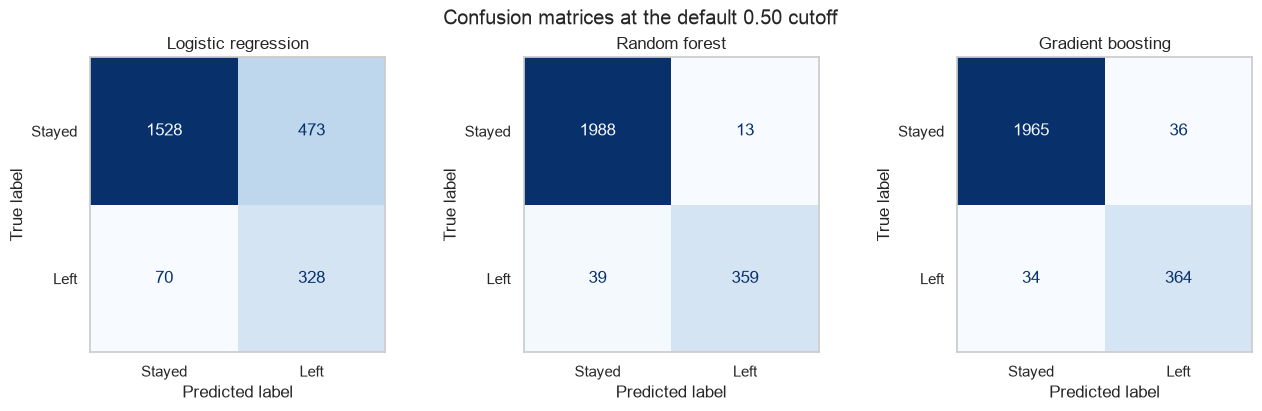

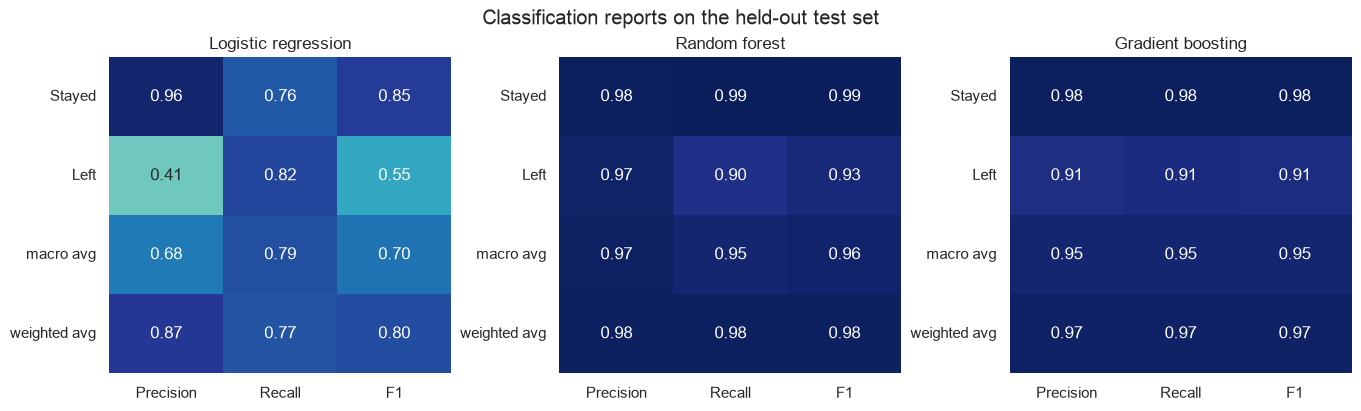

Class support: Stayed = 2,001, Left = 398


In [7]:
probabilities = {}
predictions = {}
reports = {}
test_rows = []
fig, ax = plt.subplots(figsize=(7, 5.5), layout="constrained")
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    predictions[name] = model.predict(X_test)
    reports[name] = classification_report(
        y_test, predictions[name], target_names=["Stayed", "Left"],
        output_dict=True, zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name], labels=[0, 1]).ravel()
    test_rows.append({
        "Model": name, "ROC AUC": roc_auc_score(y_test, probabilities[name]),
        "Precision (left)": reports[name]["Left"]["precision"],
        "Recall (left)": reports[name]["Left"]["recall"],
        "F1 (left)": reports[name]["Left"]["f1-score"],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set(title="ROC curves on the held-out test set")
ax.legend(loc="lower right")
plt.show()

test_summary = pd.DataFrame(test_rows).set_index("Model")
display(test_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=[0, 1], display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)
fig.suptitle("Confusion matrices at the default 0.50 cutoff")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4), layout="constrained")
for ax, (name, report) in zip(axes, reports.items()):
    rows = ["Stayed", "Left", "macro avg", "weighted avg"]
    table = pd.DataFrame({label: report[label] for label in rows}).T
    sns.heatmap(table[["precision", "recall", "f1-score"]], annot=True, fmt=".2f",
                vmin=0, vmax=1, cmap="YlGnBu", cbar=False, ax=ax)
    ax.set(title=name, ylabel="")
    ax.tick_params(axis="y", labelrotation=0)
    ax.set_xticklabels(["Precision", "Recall", "F1"])
fig.suptitle("Classification reports on the held-out test set")
plt.show()
print(f"Class support: Stayed = {(y_test == 0).sum():,}, Left = {(y_test == 1).sum():,}")

In [8]:
best = test_summary.loc[best_name]
display(Markdown(
    f"**Selected model: {best_name}.** Mean validation AP was "
    f"{cv_summary.loc[best_name, 'average_precision']:.3f}. "
    f"Held-out ROC AUC was {best['ROC AUC']:.3f}. "
    f"At the default cutoff, it identified {int(best['TP'])} of "
    f"{int(best['TP'] + best['FN'])} employees who left "
    f"(recall {best['Recall (left)']:.1%}) and missed {int(best['FN'])}. "
    f"It also flagged {int(best['FP'])} employees who stayed "
    f"(precision {best['Precision (left)']:.1%})."
))

**Selected model: Gradient boosting.** Mean validation AP was 0.967. Held-out ROC AUC was 0.977. At the default cutoff, it identified 364 of 398 employees who left (recall 91.5%) and missed 34. It also flagged 36 employees who stayed (precision 91.0%).

**Prioritize recall for the employee-left class** when outreach is supportive and the cost of missing an employee at risk outweighs the cost of an extra check-in. Recall measures how many actual departures the model flags. Precision measures how many flagged employees actually left and helps estimate the burden of unnecessary outreach. F1 summarizes the balance between the two. ROC AUC describes ranking across thresholds, and AP focuses on positive-class retrieval. Accuracy alone could hide missed departures because most employees stayed.

## 7. Risk zones and retention strategies

Apply the selected model to every held-out record. The assignment leaves scores exactly equal to 20%, 60%, or 90% undefined. Assign each boundary to the higher zone so all scores are covered. Use the raw model probabilities as risk scores. SMOTE changes the training class balance, and these scores have not been calibrated to real-world turnover frequencies.

In [9]:
zone_labels = ["Safe (Green)", "Low (Yellow)", "Medium (Orange)", "High (Red)"]
risk = pd.DataFrame({
    "source_record": y_test.index + 1,
    "actual_left": y_test.to_numpy(),
    "turnover_score": probabilities[best_name],
})
risk["risk_zone"] = pd.cut(
    risk["turnover_score"], bins=[0, .20, .60, .90, float("inf")],
    labels=zone_labels, right=False,
)
assert risk["risk_zone"].notna().all()
zone_summary = risk.groupby("risk_zone", observed=False).agg(
    employees=("source_record", "size"),
    actual_departures=("actual_left", "sum"),
    observed_turnover=("actual_left", "mean"),
)
assert zone_summary["employees"].sum() == len(y_test)
assert zone_summary["actual_departures"].sum() == y_test.sum()
display(zone_summary.style.format({"observed_turnover": "{:.1%}"}, na_rep="—"))
risk.sort_values("turnover_score", ascending=False).to_csv(
    "test_employee_risk_scores.csv", index=False
)
print("Wrote all held-out scores to test_employee_risk_scores.csv.")

,employees,actual_departures,observed_turnover
risk_zone,,,
Safe (Green),1889,26,1.4%
Low (Yellow),124,10,8.1%
Medium (Orange),40,23,57.5%
High (Red),346,339,98.0%


Wrote all held-out scores to test_employee_risk_scores.csv.


| Risk zone | Score range | Suggested retention response |
|---|---|---|
| Safe · Green | Below 20% | Keep regular one-on-ones, recognize good work, and make development opportunities accessible. |
| Low · Yellow | 20% to below 60% | Schedule a short check-in about workload, career goals, and support. Agree on one follow-up action if the employee identifies a concern. |
| Medium · Orange | 60% to below 90% | Offer a stay interview. Review project load, role fit, pay equity, or promotion barriers as appropriate. Agree on a concrete action and a follow-up date. |
| High · Red | 90% and above | Prioritize a confidential stay interview and offer timely support. Work with HR and the employee on options such as workload relief, a role change, or a compensation review based on the concerns raised. |

The score is a prompt for human review. Retention decisions should use the employee's own feedback and current circumstances. The source record number in the export is the one-based data-row position in the original CSV, excluding the header.